In [337]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [338]:
## part 1: finding the response
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47 

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.6,speckle_window=50)
PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

least-squares solution: (0.9010065546711343,0.7686451773393917)
Estimated dispersion direction 40.46736538361693°
Estimated dispersion magnitude 1.184326061609493
dx: 0.9010065546711343
dy: 0.7686451773393917


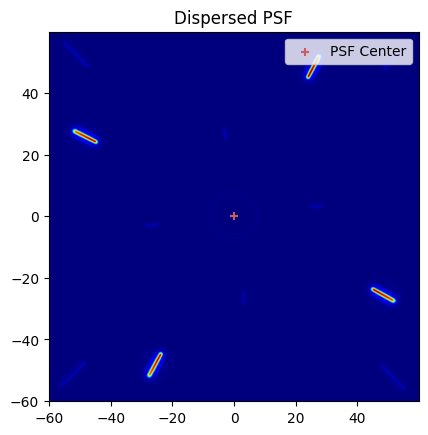

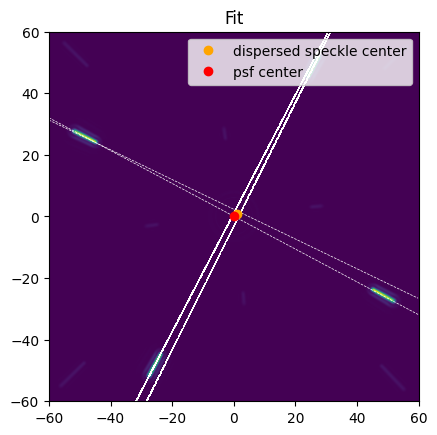

In [412]:
disp = 0.01
dir = 45

disp_x = np.cos(np.radians(dir)) * disp
disp_y = np.sin(np.radians(dir)) * disp

num_photons = 1E12
psf = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=num_photons,ptv=0)

true_center = np.array([0,0]) #we can worry about how well we can estimate this later

imshow_field(psf,cmap='jet')
plt.scatter(true_center[0],true_center[1],marker='+',color='indianred',label='PSF Center')
plt.legend()
plt.title('Dispersed PSF')

plt.figure()
est = ADC.speckles_dxdy(psf,plotted=True,printed=True)
print(f'dx: {est[0]}')
print(f'dy: {est[1]}')
plt.title('Fit')
plt.show()

In [426]:
#these angles are just wrong!! we need to be measuring them with respect to the same relative axis on all four, and we're just not
#also note that it will blow up only if the angles are equal in magnitude and opposite in sign
#we know the separation between a pair of speckles is 2*47 = 94 lam/D
disp = 0.05
dir = 28

disp_x = np.cos(np.radians(dir)) * disp
disp_y = np.sin(np.radians(dir)) * disp

num_photons = 1E12
psf = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_y,num_photons=num_photons,ptv=0)

s = ADC.all_speckle_angles(psf)
print(s)
ga = ADC.grating_angle

sep = ADC.grating_freq * 2 * ADC.normalized_wavelength #normalize because the pixels are in lam/D at Ha
d1 = sep * np.sin(np.radians(s[2]-ga))*np.sin(np.radians(ga-s[0])) / np.sin(np.radians((ga-s[0]) + (s[2]-ga)))
d2 = sep * np.sin(np.radians(-s[1]-ga))*np.sin(np.radians(ga + s[3])) / np.sin(np.radians((-s[1]-ga) + (ga + s[3])))

print(d1)  
print(d2)

#apply rotation matrix in the opposite direction of the grating angle
dx = np.cos(np.radians(-ga)) * d1 - np.sin(np.radians(-ga)) * d2
dy = np.sin(np.radians(-ga)) * d1 + np.cos(np.radians(-ga)) * d2

print(f'dy: {dy}')
print(f'dx: {dx}')
print(f'est magnitude: {np.sqrt(dx**2 + dy**2)}')
print(f'est dir: {np.degrees(np.atan2(dx,dy))}')

[ 22.99608407 -31.75140289  30.23840577 -22.51939727]
2.9584221946006113
4.2641133862440785
dy: 2.3760935589821233
dx: 4.6140117307192785
est magnitude: 5.189886786072645
est dir: 62.75273471138095


In [427]:
print(ga-s[0])
print(s[2]-ga)

5.003915931005935
2.2384057737933425


In [406]:
#wrap it up in a function
def dxdy(s):
    ga = ADC.grating_angle

    sep = ADC.grating_freq * 2 * ADC.normalized_wavelength 
    d1 = sep * np.sin(np.radians(s[2]-ga))*np.sin(np.radians(ga-s[0])) / np.sin(np.radians((ga-s[0]) + (s[2]-ga)))
    d2 = sep * np.sin(np.radians(-s[1]-ga))*np.sin(np.radians(ga + s[3])) / np.sin(np.radians((-s[1]-ga) + (ga + s[3])))

    #apply rotation matrix in the opposite direction of the grating angle
    dx = np.cos(np.radians(-ga)) * d1 - np.sin(np.radians(-ga)) * d2
    dy = np.sin(np.radians(-ga)) * d1 + np.cos(np.radians(-ga)) * d2

    return dx, dy

dx, dy = dxdy(s)
print(f'dy: {dy}')
print(f'dx: {dx}')
print(f'est magnitude: {np.sqrt(dx**2 + dy**2)}')
print(f'est dir: {np.degrees(np.atan2(dx,dy))}')


dy: 1.41519029203518
dx: 0.5495851661871064
est magnitude: 1.5181592200963399
est dir: 21.22354052170508


In [ ]:
#calculate the response

injected dispersion dx: 0.04949747468305833 dy: -0.049497474683058325
est disp 7.73120525514967
est ang 130.20917403217143
IV
est ADC shear angle: -5.947080965499746°
est ADC rot angle: 130.20917403217143°
remaining dispersion: -0.0002836841377242688
remaining axis offset 85.20917403217143


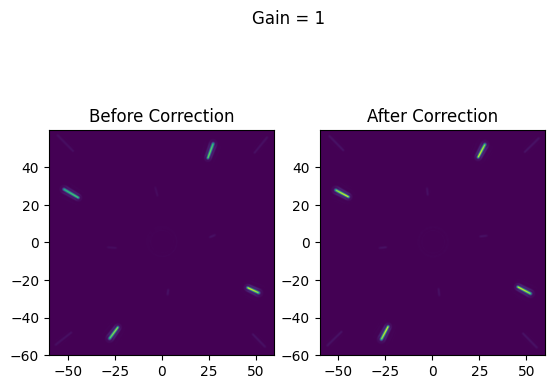

In [379]:
#single shot control
#one single iteration with a gain of one, before I put it in an integrator
#the response
m00 = 1/1.3 #degrees/pixel
m01 = 1 #degrees/degree 
m02 = 110 #pixels/arb. dispersion input

#set up dispersed PSF
disps =  .07 #np.abs(np.random.randn(1))#-0.08 + np.abs(np.random.randn(1))*.02
dir = -45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')

psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)

fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

#now try and measure it

s = ADC.all_speckle_angles(psf)
est_x, est_y = dxdy(s)
sq = np.sqrt(est_x**2+est_y**2)
ang = np.degrees(np.arctan2(est_x,est_y))
print(f'est disp {sq}')
print(f'est ang {ang}')

#calculate how much to move ADCs
#get the correct quadrant
if est_x >0 and est_y>0: #quadrant I
    print('I')
    mag_sign = -1 #we want to subtract this dispersion
    ang_sign = -1 #and subtract the angle 
elif est_x <0 and est_y>0: #quadrant II
    print('II')
    mag_sign = 1 #we want to add dispersion (because the dispersion is negative)
    ang_sign = -1 #and subtract the angle (because it's negative and we want to add it)
elif est_x <0 and est_y<0: #quadrant III
    print('III')
    mag_sign = -1 #we would add the dispersion (because it's negative), but we changed the rotation sign
    ang = 180 - ang #we want to reverse the direction and change the sign of the magnitude
    ang_sign = -1 # i think we want to subtract the new angle??
else: #quadrant IV
    print('IV')
    mag_sign = -1
    ang = ang#180 - ang
    ang_sign = 1
    
shear_est = mag_sign * m00 * sq
rot_est = ang_sign * ang #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
print(f'est ADC shear angle: {shear_est}°')
print(f'est ADC rot angle: {rot_est}°')

#integrate (gain of one)
disps =  disps + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
dir = dir + rot_est
disps_x = np.cos(np.radians(dir)) * disps
disps_y = np.sin(np.radians(dir)) * disps
psf = PsfGen.psf(magnitude_x=disps_x,magnitude_y=disps_y)
print(f'remaining dispersion: {disps}')
print(f'remaining axis offset {dir}')

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle('Gain = 1')
plt.show()

#need to make the change - if the angle is measured greater than 90°, we should subtract 180 from it and then give the magnitude a negative mag_sign
#is this even correct? i don't think so
# we can only compensate the shear along the axis that we're oriented - we can't control the shear independently of the orientation
# this goes back to the cosine problem we're trying to solve in the first place
# we'd have to correct all the angle offset and /then/ move onto doing the shearing
# if we want to correct both gradually, then we have to take into account the fact that the response changes alongside the angle offset
# can we just calculate what needs to happen to adc1 and adc2 individually instead of doing a magnitude/orientation??
# yeah let's do it that way. calculate what dadc1 and dadc2 would be every iteration

In [378]:
np.angle(ang)

np.float64(0.0)

injected dispersion dx: 0.05656854249492381 dy: 0.056568542494923796


/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


est disp 8.655068802472098
est ang 42.32328768479324
est ADC shear angle: -6.657745232670844°
est ADC rot angle: -42.32328768479324°
est disp 5.492170066261066
est ang -17.154471588741494
est ADC shear angle: -2.43299902785464°
est ADC rot angle: -59.47775927353474°
est disp 5.6815130703606584
est ang 111.53043152445382
est ADC shear angle: -6.803393697362838°
est ADC rot angle: -171.00819079798856°
est disp 5.525056246855197
est ang -20.87791396550112
est ADC shear angle: -2.5533504305511485°
est ADC rot angle: -191.88610476348967°
est disp 5.2191254255991355
est ang -134.40024450614584
est ADC shear angle: 1.4613614352943403°
est ADC rot angle: -326.2863492696355°
est disp 10.300126940516455
est ang 11.764778247034307
est ADC shear angle: -6.461813134333701°
est ADC rot angle: -338.0511275166698°
est disp 5.790021601693967
est ang -122.95700925940656
est ADC shear angle: -2.00795036379988°
est ADC rot angle: -461.00813677607636°
est disp 6.378886044088569
est ang 144.49659400326635
e

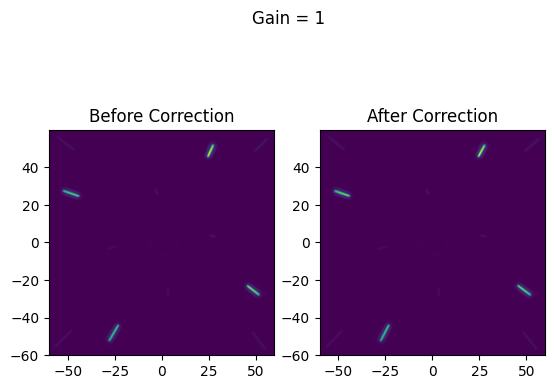

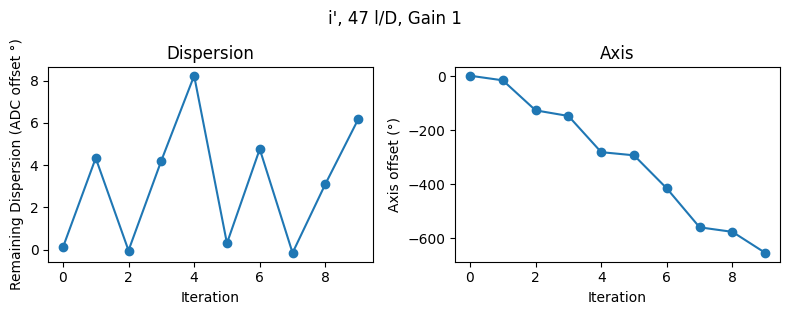

In [423]:
#let's try and do some control using this method instead of knowing the center 
m00 = 1/1.3 #degrees/pixel
m01 = 1 #degrees/degree 
m02 = 110 #pixels/arb. dispersion input

induced_disp =  .08 #*np.abs(np.random.randn(1))
induced_dir = 45 #degrees - dispersion vector orientation
disps_x = np.cos(np.radians(induced_dir)) * induced_disp
disps_y = np.sin(np.radians(induced_dir)) * induced_disp
print(f'injected dispersion dx: {disps_x} dy: {disps_y}')
shear_est = 0
rot_est = 0

num_iterations = 10

gain = 1

disp_tracker = []
ang_tracker = []

psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E12,ptv=0)
fig, ax = plt.subplots(1,2)
imshow_field(psf,ax=ax[0])
ax[0].set_title('Before Correction')

for i in range(num_iterations):
    s = ADC.all_speckle_angles(psf)
    est_x, est_y = dxdy(s)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_x,est_y))
    print(f'est disp {sq}')
    print(f'est ang {ang}')

    if est_x >0 and est_y>0:
        sign = -1
    elif est_x <0 and est_y>0:
        sign = 1
    elif est_x <0 and est_y<0:
        sign = 1
    else: sign = -1
        
    shear_est += m00 * sq * gain * sign
    rot_est += ang * gain *sign #this is 1:1, measuring from the x-axis in this simulation (irl it's the y-axis)
    print(f'est ADC shear angle: {shear_est}°')
    print(f'est ADC rot angle: {rot_est}°')

    #integrate (gain of one)
    disps = induced_disp + shear_est * 1/m00 * 1/m02 #deg * px/deg * arb./px
    dir = induced_dir + rot_est
    disps_x = np.cos(np.radians(dir)) * disps
    disps_y = np.sin(np.radians(dir)) * disps
    # print(f'remaining dispersion: {disps}')
    # print(f'remaining axis offset {dir}')
    disp_tracker.append(disps)
    ang_tracker.append(dir)

    psf = PsfGen.noisy_turbulent_psf(magnitude_x=disps_x,magnitude_y=disps_y,num_photons=1E12,ptv=0)

disp_tracker = np.array(disp_tracker) * m02 * m00

imshow_field(psf,ax=ax[1])
ax[1].set_title('After Correction')
fig.suptitle(f'Gain = {gain}')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(disp_tracker,'o-')
ax[0].set_title('Dispersion')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Remaining Dispersion (ADC offset °)')

ax[0].set_box_aspect(0.6)

ax[1].plot(ang_tracker,'o-')
ax[1].set_title('Axis')
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Axis offset (°)')
ax[1].set_box_aspect(0.6)

fig.suptitle(f'i\', 47 l/D, Gain {gain}')
fig.tight_layout()
plt.show()
